## Numerical illustration for "Factorization Error and Optimal Schedules in Masked Discrete Diffusion".

For two example targets we compute the dependence density rho, the eps_fact-optimal
schedule, the linear schedule, and the resulting factorization error:

    (1) stationary 10-state lazy walk on a sparse random-weight graph -> LOCAL dependence (Prop. markov-example)
    (2) Beta-Bernoulli exchangeable model -> GLOBAL dependence  (Prop. exchangeable-example)

Formulas (paper numbering):
    eps_fact(beta) = N * sum_k int_{b_{k-1}}^{b_k} (b_k - u) rho(u) du          [Thm. main]
    D(pi) = int_0^1 rho,   TC = N int (1-u) rho,   DTC = N int u rho            [Lemma correlation]
    Markov:        rho_N(u) = sum_{d=1}^{N-1} (1 - d/N) I_d * w_d''(u),  w_d=u^2(1-u)^{d-1}
                   I_d = I(X^0;X^d) = h_0 - h_d
    Exchangeable:  rho_N(u) = (N-1) sum_{m=0}^{N-2} g_m * Bernstein_{m,N-2}(u)
                   g_m = I(X^{m+1};X^{m+2} | X^{1:m})

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gammaln


In [2]:

# ----------------------------------------------------------------- utilities
def entropy(p):
    p = np.asarray(p, float)
    p = p[p > 1e-300]
    return float(-np.sum(p * np.log(p)))

def integration_grid(M=4000):
    # dense near 0 (the exchangeable rho concentrates there), uniform elsewhere
    near0 = np.geomspace(1e-9, 0.05, M // 2)
    mid = np.linspace(0.05, 1.0, M - M // 2)
    return np.unique(np.concatenate(([0.0], near0, mid)))

# ----------------------------------------------------------------- eps_fact
def make_eps_fact(U, rho_vals, N):
    """Return eps_fact(beta) plus cumulative integrals A0=int_0^x rho, A1=int_0^x u rho."""
    A0 = np.concatenate(([0.0],
        np.cumsum(0.5 * (rho_vals[1:] + rho_vals[:-1]) * np.diff(U))))
    uR = U * rho_vals
    A1 = np.concatenate(([0.0],
        np.cumsum(0.5 * (uR[1:] + uR[:-1]) * np.diff(U))))
    D = A0[-1]                                   # int_0^1 rho = D(pi)
    def eps_fact(beta):                          # beta = full vector [0, ..., 1]
        a0 = np.interp(beta, U, A0)
        a1 = np.interp(beta, U, A1)
        bk = beta[1:]
        return float(N * np.sum(bk * (a0[1:] - a0[:-1]) - (a1[1:] - a1[:-1])))
    return eps_fact, A0, A1, D

def linear_schedule(K):
    return np.linspace(0.0, 1.0, K + 1)


def optimal_schedule(K, eps_fact_fn, U, rho_vals, A0):
    """
    Cor. recursive (eq. recursive formula):

        beta_{k+1} = beta_k + [A0(beta_k) - A0(beta_{k-1})] / rho(beta_k)

    Shooting in beta_1: run the recurrence and measure how many full steps it
    takes to reach or exceed 1.  The correct beta_1 is the one for which the
    recurrence completes in exactly K steps.

    shoot(b1) returns beta_K (the K-th iterate without clamping); for log concave rho, it is
    strictly increasing in b1, goes from ~0 (tiny b1) to >1 (large b1),
    so brentq finds the unique zero of shoot(b1) - 1.
    """
    from scipy.optimize import brentq

    def shoot(b1):
        """Run K steps of the recurrence without clamping; return beta_K."""
        prev, cur = 0.0, float(b1)
        for _ in range(K - 1):
            mass  = float(np.interp(cur, U, A0) - np.interp(prev, U, A0))
            rho_k = float(np.interp(cur, U, rho_vals))
            if rho_k < 1e-14:
                return cur          # flat rho: treat cur as the endpoint
            prev, cur = cur, cur + mass / rho_k
        return cur                  # = beta_K (unclamped)

    # bracket: shoot(lo) < 1 < shoot(hi)
    lo, hi = 1e-12, 1.0 - 1e-10
    assert shoot(lo) < 1.0, "shoot(lo) must be < 1"
    assert shoot(hi) > 1.0, "shoot(hi) must be > 1"

    b1_opt = brentq(lambda b: shoot(b) - 1.0, lo, hi, xtol=1e-12, rtol=1e-12)

    # reconstruct full schedule with clamping
    beta = [0.0, b1_opt]
    for _ in range(K - 1):
        bk, bkm1 = beta[-1], beta[-2]
        mass  = float(np.interp(bk, U, A0) - np.interp(bkm1, U, A0))
        rho_k = float(np.interp(bk, U, rho_vals))
        if rho_k < 1e-14:
            remaining = K - len(beta) + 1
            step = (1.0 - bk) / remaining
            beta += [bk + step * i for i in range(1, remaining + 1)]
            break
        beta.append(min(1.0, bk + mass / rho_k))
        if beta[-1] >= 1.0:
            break
    while len(beta) < K + 1:
        beta.append(1.0)
    beta = np.array(beta[:K + 1]); beta[-1] = 1.0
    return beta, float(eps_fact_fn(beta))



In [3]:
# Example 1: Markov
def w2(u, d):
    """Second derivative of w_d(u) = u^2 (1-u)^{d-1}, stable on [0,1]."""
    om = 1.0 - u
    if d == 1:
        return np.full_like(u, 2.0)
    if d == 2:
        return 2.0 - 6.0 * u
    return om ** (d - 3) * (2.0 * om ** 2 - 4.0 * (d - 1) * u * om
                            + (d - 1) * (d - 2) * u ** 2)

def stationary_distribution(P):
    """Compute the stationary distribution of an irreducible transition matrix."""
    K = P.shape[0]
    A = P.T - np.eye(K)
    A[-1] = 1.0
    b = np.zeros(K); b[-1] = 1.0
    mu = np.linalg.solve(A, b)
    if np.any(mu < -1e-10):
        raise ValueError("Failed to compute a nonnegative stationary distribution")
    mu = np.clip(mu, 0.0, None)
    return mu / mu.sum()

def markov_Id(P, N):
    K = P.shape[0]
    mu = stationary_distribution(P)
    h0 = entropy(mu)
    I = np.zeros(N); Pd = np.eye(K)
    for d in range(1, N):
        Pd = Pd @ P
        hd = sum(mu[a] * entropy(Pd[a]) for a in range(K))
        I[d] = max(h0 - hd, 0.0)
    return I, h0

def rho_markov(U, I, N, weight=True):
    rho = np.zeros_like(U)
    for d in range(1, N):
        if I[d] < 1e-14:
            continue
        wt = (1.0 - d / N) if weight else 1.0
        rho += wt * I[d] * w2(U, d)
    return rho

def lazy_sparse_random_transition(n_states=10, laziness=0.50, n_shortcuts=3, seed=2026):
    """Lazy walk on a sparse connected graph with reproducible random weights.

    A randomly weighted cycle guarantees connectivity. A small number of
    randomly chosen non-neighbour edges adds long-range dependence while the
    graph remains sparse. Symmetric weights make the chain reversible, and
    the positive diagonal introduced by laziness makes it aperiodic.
    """
    if n_states < 4:
        raise ValueError("n_states must be at least 4")
    if not 0.0 < laziness < 1.0:
        raise ValueError("laziness must lie strictly between 0 and 1")

    rng = np.random.default_rng(seed)
    W = np.zeros((n_states, n_states))

    # Randomly weighted cycle: exactly n_states edges, hence connected.
    cycle_pairs = set()
    for i in range(n_states):
        j = (i + 1) % n_states
        pair = tuple(sorted((i, j)))
        cycle_pairs.add(pair)
        weight = rng.uniform(0.60, 1.40)
        W[i, j] = W[j, i] = weight

    # Select a few non-neighbour shortcuts without replacement.
    candidates = [
        (i, j) for i in range(n_states) for j in range(i + 1, n_states)
        if (i, j) not in cycle_pairs
    ]
    if not 0 <= n_shortcuts <= len(candidates):
        raise ValueError("invalid number of shortcuts")
    chosen = rng.choice(len(candidates), size=n_shortcuts, replace=False)
    for index in np.atleast_1d(chosen):
        i, j = candidates[int(index)]
        weight = rng.uniform(0.30, 1.00)
        W[i, j] = W[j, i] = weight

    Q = W / W.sum(axis=1, keepdims=True)
    P = laziness * np.eye(n_states) + (1.0 - laziness) * Q
    return P



In [4]:
#  Example 2: exchangeable
def cond_MI_given_s(s, m, a, b):
    """I(X_{m+1};X_{m+2} | counts) for Beta(a,b)-Bernoulli with s ones among m."""
    tot = a + b + m
    p1 = (a + s) / tot
    t2 = tot + 1.0
    # P(X_{m+1}=i, X_{m+2}=j | s) = P(X_{m+1}=i | s) · P(X_{m+2}=j | s, X_{m+1}=i)
    P = np.array([
        [(1 - p1) * (b + (m - s) + 1) / t2, (1 - p1) * (a + s) / t2],   # X_{m+1}=0
        [p1 * (b + (m - s)) / t2,           p1 * (a + s + 1) / t2],     # X_{m+1}=1
    ])
    Pr = P.sum(1, keepdims=True); Pc = P.sum(0, keepdims=True)
    prod = Pr @ Pc
    mask = P > 1e-300
    return float(np.sum(P[mask] * np.log(P[mask] / prod[mask])))

def betabinom_logpmf(s, m, a, b):
    return (gammaln(m + 1) - gammaln(s + 1) - gammaln(m - s + 1)
            + gammaln(s + a) + gammaln(m - s + b) - gammaln(m + a + b)
            + gammaln(a + b) - gammaln(a) - gammaln(b))

def exch_gm(N, a=1.0, b=1.0):
    #g_m = I(X_{m+1}; X_{m+2} | X_{1:m}) = E_{S_m}[I(X_{m+1}; X_{m+2} | S_m)]
    #    = Σ_{s=0}^{m} P(S_m = s) · I(X_{m+1}; X_{m+2} | S_m = s)
    g = np.zeros(N - 1)                         # g[m], m = 0 .. N-2
    for m in range(0, N - 1):
        s = np.arange(0, m + 1)
        w = np.exp(betabinom_logpmf(s, m, a, b))
        g[m] = float(np.sum([w[k] * cond_MI_given_s(int(s[k]), m, a, b)
                             for k in range(len(s))]))
    return g

def rho_exch(U, g, N):
    # ρ_N(u) = (N−1) Σ_{m=0}^{N-2} g_m · B_{m,N-2}(u)
    M = N - 2
    rho = np.zeros_like(U)
    logc = gammaln(M + 1) - gammaln(np.arange(M + 1) + 1) - gammaln(M - np.arange(M + 1) + 1)
    with np.errstate(divide="ignore"):
        logu = np.log(np.clip(U, 1e-300, 1.0))
        log1mu = np.log(np.clip(1.0 - U, 1e-300, 1.0))
    for m in range(0, M + 1):
        if g[m] < 1e-16:
            continue
        B = np.exp(logc[m] + m * logu + (M - m) * log1mu)
        rho += (N - 1) * g[m] * B
    return rho



In [5]:
#  build
def K_of(N):
    return 1 + int(np.ceil(np.log2(N)))      # logarithmic step budget (Prop. comparison-schedules)

U = integration_grid(4000)
N_demo = 256
K_demo = K_of(N_demo)

# --- Markov chain: lazy sparse random-weighted cycle with shortcuts ---
# N_demo is the sequence length; n_states is the Markov state-space size.
n_states = 10
n_shortcuts = 5
random_seed = 2026
P = lazy_sparse_random_transition(
    n_states=n_states, laziness=0.50, n_shortcuts=n_shortcuts, seed=random_seed
)
assert np.allclose(P.sum(axis=1), 1.0)
assert np.all(np.diag(P) > 0.0)                         # lazy => aperiodic
support = (P > 0.0).astype(int)
assert np.all(np.linalg.matrix_power(support, n_states - 1) > 0)  # irreducible
mu_mk = stationary_distribution(P)
n_edges = int(np.count_nonzero(np.triu(P > 0.0, k=1)))
print(f"=== {n_states}-state sparse random-weight lazy Markov matrix ===")
print(f"undirected edges: {n_edges} = {n_states} cycle + {n_shortcuts} shortcuts")
print(np.array2string(P, precision=3, suppress_small=True))
print("stationary distribution:", np.round(mu_mk, 3))
print()
I_mk, h0_mk = markov_Id(P, N_demo)
rho_mk = rho_markov(U, I_mk, N_demo, weight=True)
g_mk = rho_markov(U, I_mk, N_demo, weight=False)          # ~ limiting profile g
f_mk, A0_mk, A1_mk, D_mk = make_eps_fact(U, rho_mk, N_demo)

# --- Beta-Bernoulli exchangeable (uniform prior a=b=1) ---
gcoef_ex = exch_gm(N_demo, 1.0, 1.0)
rho_ex = rho_exch(U, gcoef_ex, N_demo)
f_ex, A0_ex, A1_ex, D_ex = make_eps_fact(U, rho_ex, N_demo)

print("=== sanity checks ===")
print(f"Markov  N={N_demo}: int rho = D = {D_mk:.5f},  rho>=0: {np.all(rho_mk > -1e-9)}")
print(f"Exch    N={N_demo}: int rho = {D_ex:.5f}  vs  sum_m g_m = {gcoef_ex.sum():.5f}"
      f"  (should match),  rho>=0: {np.all(rho_ex > -1e-9)}")

# --- schedules at N_demo with logarithmic budget K_demo ---
beta_lin = linear_schedule(K_demo)
beta_opt_mk, e_opt_mk = optimal_schedule(K_demo, f_mk, U, rho_mk, A0_mk)
beta_opt_ex, e_opt_ex = optimal_schedule(K_demo, f_ex, U, rho_ex, A0_ex)
e_lin_mk, e_lin_ex = f_mk(beta_lin), f_ex(beta_lin)
print(f"\n=== schedules (N={N_demo}, K={K_demo}) ===")
print(f"Markov: eps_lin = {e_lin_mk:.4f},  eps_opt = {e_opt_mk:.4f},  ratio = {e_lin_mk/e_opt_mk:.3f}")
print(f"Exch  : eps_lin = {e_lin_ex:.4f},  eps_opt = {e_opt_ex:.4f},  ratio = {e_lin_ex/e_opt_ex:.3f}")

# --- dichotomy: improvement ratio vs N with K_N = ceil(log2 N)+1 ---
Ns = np.array([8, 16, 32, 64, 128, 256, 512, 1024])
ratio_mk, ratio_ex = [], []
for N in Ns:
    KN = K_of(N)
    Im, _ = markov_Id(P, N)
    rm = rho_markov(U, Im, N, weight=True)
    fm, _A0m, _, _ = make_eps_fact(U, rm, N)
    _, eo = optimal_schedule(KN, fm, U, rm, _A0m)
    ratio_mk.append(fm(linear_schedule(KN)) / eo)

    ge = exch_gm(N, 1.0, 1.0)
    re = rho_exch(U, ge, N)
    fe, _A0e, _, _ = make_eps_fact(U, re, N)
    _, eo = optimal_schedule(KN, fe, U, re, _A0e)
    ratio_ex.append(fe(linear_schedule(KN)) / eo)
ratio_mk, ratio_ex = np.array(ratio_mk), np.array(ratio_ex)
print("\n=== dichotomy (ratio eps_lin/eps_opt vs N, K = ceil(log2 N)+1) ===")
for N, rm, re in zip(Ns, ratio_mk, ratio_ex):
    print(f"  N={N:4d} (K={K_of(N)}): Markov {rm:6.2f}   Exchangeable {re:7.2f}")

# reference rate N/(log N)^2 for the exchangeable curve (constant fit by least squares in log space)
ref_shape = Ns / np.log(Ns) ** 2
logC = np.mean(np.log(ratio_ex) - np.log(ref_shape))
ref_ex = np.exp(logC) * ref_shape

#rho of the markov model at a few N
rho_markov_byN = {N: rho_markov(U, markov_Id(P, N)[0], N, weight=True) for N in (64, 128, 256, 512)}

# rho of the exchangeable model at a few N (concentration at 0)
rho_ex_byN = {N: rho_exch(U, exch_gm(N, 1.0, 1.0), N) for N in (64, 128, 256, 512)}



=== 10-state sparse random-weight lazy Markov matrix ===
undirected edges: 15 = 10 cycle + 5 shortcuts
[[0.5   0.169 0.    0.    0.    0.    0.    0.14  0.    0.191]
 [0.155 0.5   0.232 0.    0.    0.112 0.    0.    0.    0.   ]
 [0.    0.267 0.5   0.233 0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.206 0.5   0.19  0.    0.    0.    0.    0.105]
 [0.    0.    0.    0.252 0.5   0.248 0.    0.    0.    0.   ]
 [0.    0.067 0.    0.    0.111 0.5   0.154 0.    0.11  0.057]
 [0.    0.    0.    0.    0.    0.241 0.5   0.259 0.    0.   ]
 [0.115 0.    0.    0.    0.    0.    0.247 0.5   0.138 0.   ]
 [0.    0.    0.    0.    0.    0.16  0.    0.135 0.5   0.205]
 [0.144 0.    0.    0.085 0.    0.079 0.    0.    0.193 0.5  ]]
stationary distribution: [0.085 0.093 0.081 0.092 0.069 0.155 0.099 0.104 0.107 0.113]

=== sanity checks ===
Markov  N=256: int rho = D = 1.56381,  rho>=0: True
Exch    N=256: int rho = 0.19122  vs  sum_m g_m = 0.19122  (should match),  rho>=0: True

=== schedules 

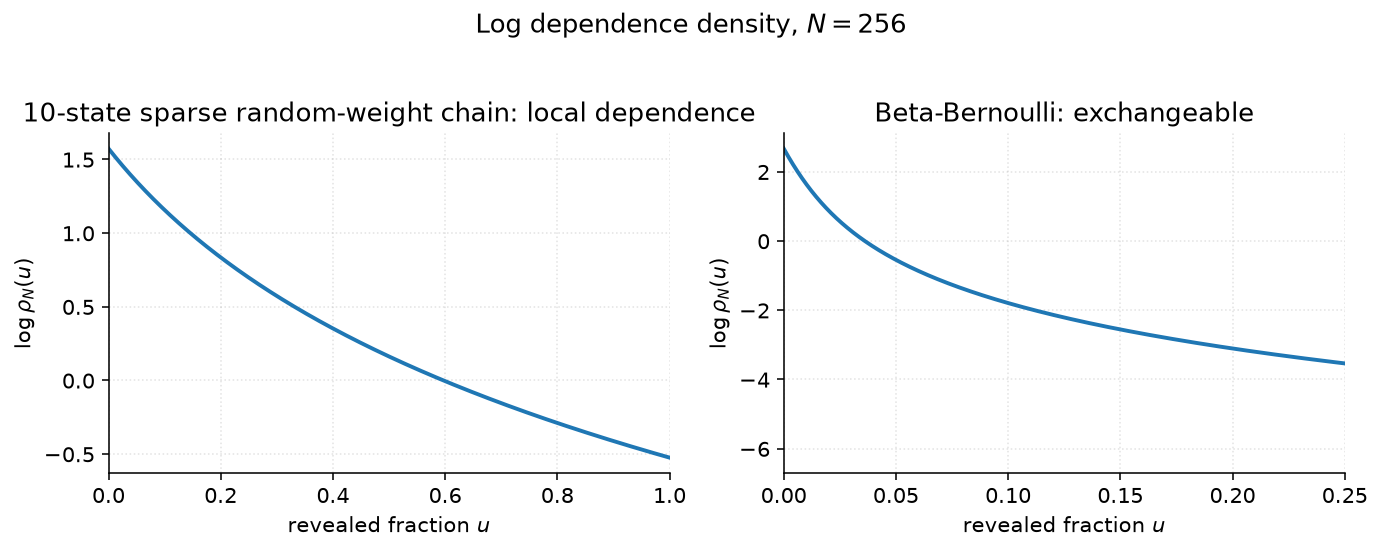

In [6]:

# ------------------------------------------------------------
# Plot log rho
# ------------------------------------------------------------
from IPython.display import display

mask_mk = rho_mk > 0
mask_ex = rho_ex > 0

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 140,
    "lines.linewidth": 2,
})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

ax[0].plot(U[mask_mk], np.log(rho_mk[mask_mk]))
ax[0].set_title("10-state sparse random-weight chain: local dependence")
ax[0].set_xlabel(r"revealed fraction $u$")
ax[0].set_ylabel(r"$\log \rho_N(u)$")
ax[0].set_xlim(0, 1)
ax[0].grid(True, ls=":", alpha=0.35)

ax[1].plot(U[mask_ex], np.log(rho_ex[mask_ex]))
ax[1].set_title("Beta-Bernoulli: exchangeable")
ax[1].set_xlabel(r"revealed fraction $u$")
ax[1].set_ylabel(r"$\log \rho_N(u)$")
ax[1].set_xlim(0, 0.25)
ax[1].grid(True, ls=":", alpha=0.35)

fig.suptitle(rf"Log dependence density, $N={N_demo}$", y=1.03)
fig.tight_layout()



In [7]:
"""
Uniqueness check for the eps_fact-optimal schedule.

Two independent checks:
  (1) Root count: scan shoot(b1) - 1 on a dense grid and count sign changes.
      Exactly one sign change => unique schedule satisfying the first-order
      conditions of Cor. recursive.
  (2) Multi-start: minimise eps_fact from 50 random initial schedules and
      verify all converge to the same value.
"""
import numpy as np
from scipy.optimize import minimize


U_ck  = integration_grid(6000)
N_ck  = 96
K_ck  = 1 + int(np.ceil(np.log2(N_ck)))   # = 8
n_states_ck = 10

# --- build rho for both examples ---
P = lazy_sparse_random_transition(
    n_states=n_states_ck, laziness=0.50, n_shortcuts=n_shortcuts, seed=2026
)
I_mk, _ = markov_Id(P, N_ck)
rho_mk   = rho_markov(U_ck, I_mk, N_ck)
f_mk, A0_mk, _, _ = make_eps_fact(U_ck, rho_mk, N_ck)

g_ex    = exch_gm(N_ck, 1.0, 1.0)
rho_ex  = rho_exch(U_ck, g_ex, N_ck)
f_ex, A0_ex, _, _ = make_eps_fact(U_ck, rho_ex, N_ck)

# ------------------------------------------------------------------ helpers
def shoot(b1, rho, A0):
    """Run K steps of the recurrence without clamping; return beta_K."""
    prev, cur = 0.0, float(b1)
    for _ in range(K_ck - 1):
        mass  = float(np.interp(cur, U_ck, A0) - np.interp(prev, U_ck, A0))
        rho_k = float(np.interp(cur, U_ck, rho))
        if rho_k < 1e-14:
            return cur
        prev, cur = cur, cur + mass / rho_k
    return cur

def softmax_unpack(theta):
    d = np.exp(theta - theta.max()); d /= d.sum()
    b = np.concatenate(([0.0], np.cumsum(d))); b[-1] = 1.0
    return b

# ------------------------------------------------------------------ check 1
def check_root_count(rho, A0, name, n=3000):
    b1s = np.linspace(1e-10, 1.0 - 1e-10, n)
    sv  = np.array([shoot(b, rho, A0) for b in b1s])
    crossings = np.where(np.diff(np.sign(sv - 1.0)) != 0)[0]
    n_roots = len(crossings)
    locs    = [f"{b1s[i]:.5f}" for i in crossings]
    status  = "UNIQUE" if n_roots == 1 else f"WARNING: {n_roots} roots"
    print(f"  {name}: {n_roots} root(s) of shoot(b1)=1  at b1 ~ {locs}  -> {status}")

# ------------------------------------------------------------------ check 2
def check_multistart(f, K, name, n_starts=50, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_starts):
        inner  = np.sort(rng.uniform(0, 1, K - 1))
        beta0  = np.concatenate(([0.0], inner, [1.0]))
        d0     = np.diff(beta0); d0 = np.clip(d0, 1e-15, None)
        theta0 = np.log(d0)
        res = minimize(lambda th: f(softmax_unpack(th)), theta0,
                       method="Powell",
                       options={"maxiter": 100000, "ftol": 1e-13, "xtol": 1e-11})
        vals.append(float(res.fun))
    vals   = np.array(vals)
    spread = vals.max() - vals.min()
    n_conv = int((np.abs(vals - vals.min()) < 1e-5).sum())
    status = "UNIQUE" if spread < 1e-4 else "WARNING: possible multiple minima"
    print(f"  {name}: {n_starts} starts -> "
          f"min={vals.min():.6f}  spread={spread:.2e}  "
          f"{n_conv}/{n_starts} agree  -> {status}")

# ------------------------------------------------------------------ run
print("=" * 60)
print(f"Uniqueness checks  (N={N_ck}, K={K_ck})")
print("=" * 60)

print("\nCheck 1: root count of shoot(b1) = 1")
check_root_count(rho_mk, A0_mk, "Markov      ")
check_root_count(rho_ex, A0_ex, "Exchangeable")

print("\nCheck 2: multi-start minimisation of eps_fact")
check_multistart(f_mk, K_ck, "Markov      ")
check_multistart(f_ex, K_ck, "Exchangeable")

Uniqueness checks  (N=96, K=8)

Check 1: root count of shoot(b1) = 1
  Markov      : 1 root(s) of shoot(b1)=1  at b1 ~ ['0.07336']  -> UNIQUE
  Exchangeable: 1 root(s) of shoot(b1)=1  at b1 ~ ['0.01734']  -> UNIQUE

Check 2: multi-start minimisation of eps_fact
  Markov      : 50 starts -> min=8.933593  spread=2.52e-07  50/50 agree  -> UNIQUE
  Exchangeable: 50 starts -> min=0.496848  spread=7.68e-07  50/50 agree  -> UNIQUE



saved factorization_schedules.{pdf,png}


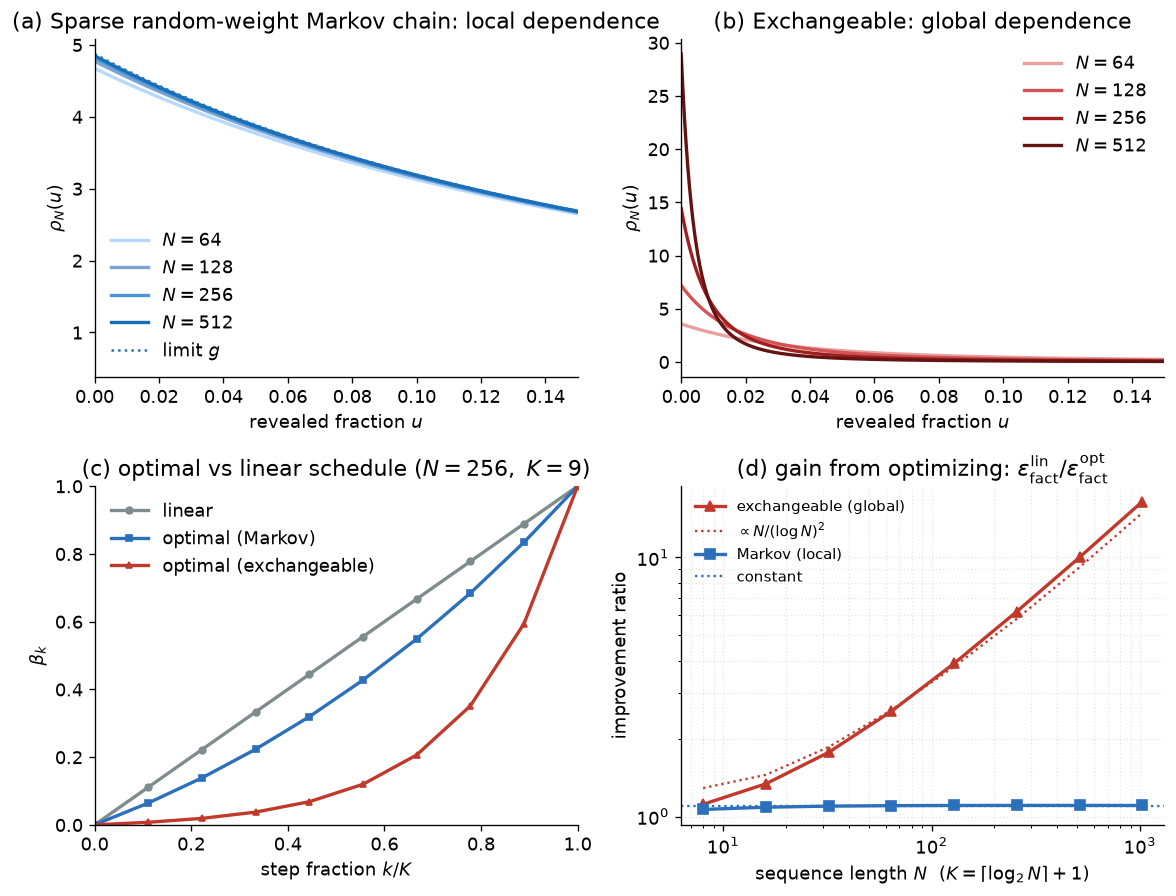

In [ ]:
# ================================================================= figure
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "lines.linewidth": 2})
C_MK, C_EX, C_LIN = "#2c6fbb", "#c0392b", "#7f8c8d"
fig, ax = plt.subplots(2, 2, figsize=(10, 7.6))
'''
# (a) rho for the Markov chain
ax[0, 0].plot(U, rho_mk, color=C_MK, label=rf"$\rho_N$, $N={N_demo}$")
ax[0, 0].plot(U, g_mk, color=C_MK, ls="--", lw=1.5, label=r"limit $g$")
ax[0, 0].set_title("(a) Sparse random-weight Markov chain: local dependence")
ax[0, 0].set_xlabel(r"revealed fraction $u$"); ax[0, 0].set_ylabel(r"$\rho(u)$")
ax[0, 0].set_xlim(0, 1); ax[0, 0].legend(frameon=False)
'''
# (a) rho for the Markov chain
for N, col in zip((64, 128, 256, 512), ("#459cff61", "#2c6eb9a0", "#2d85ceda", "#156eb8")):
    ax[0, 0].plot(U, rho_markov_byN[N], color=col, label=rf"$N={N}$")
ax[0, 0].plot(U, g_mk, color=C_MK, ls=":", lw=1.5, label=r"limit $g$")
ax[0, 0].set_title("(a) Sparse random-weight Markov chain: local dependence")
ax[0, 0].set_xlabel(r"revealed fraction $u$"); ax[0, 0].set_ylabel(r"$\rho_N(u)$")
ax[0, 0].set_xlim(0, 0.15); ax[0, 0].legend(frameon=False)



# (b) rho for the exchangeable model: concentrates at 0 as N grows
for N, col in zip((64, 128, 256, 512), ("#e8a0a0", "#d35454", "#a01e1e", "#651212")):
    ax[0, 1].plot(U, rho_ex_byN[N], color=col, label=rf"$N={N}$")
ax[0, 1].set_title("(b) Exchangeable: global dependence")
ax[0, 1].set_xlabel(r"revealed fraction $u$"); ax[0, 1].set_ylabel(r"$\rho_N(u)$")
ax[0, 1].set_xlim(0, 0.15); ax[0, 1].legend(frameon=False)

# (c) optimal vs linear schedule (N=N_demo, K=K_demo)
t = np.arange(K_demo + 1) / K_demo
ax[1, 0].plot(t, beta_lin, color=C_LIN, marker="o", ms=4, label="linear")
ax[1, 0].plot(t, beta_opt_mk, color=C_MK, marker="s", ms=4, label="optimal (Markov)")
ax[1, 0].plot(t, beta_opt_ex, color=C_EX, marker="^", ms=4, label="optimal (exchangeable)")
ax[1, 0].set_title(rf"(c) optimal vs linear schedule ($N={N_demo},\ K={K_demo}$)")
ax[1, 0].set_xlabel(r"step fraction $k/K$"); ax[1, 0].set_ylabel(r"$\beta_k$")
ax[1, 0].set_xlim(0, 1); ax[1, 0].set_ylim(0, 1); ax[1, 0].legend(frameon=False)

# (d) the dichotomy: improvement ratio vs N
ax[1, 1].loglog(Ns, ratio_ex, color=C_EX, marker="^", ms=6, label="exchangeable (global)")
ax[1, 1].loglog(Ns, ref_ex, color=C_EX, ls=":", lw=1.4, label=r"$\propto N/(\log N)^2$")
ax[1, 1].loglog(Ns, ratio_mk, color=C_MK, marker="s", ms=6, label="Markov (local)")
ax[1, 1].axhline(ratio_mk.mean(), color=C_MK, ls=":", lw=1.4, label="constant")
ax[1, 1].set_title(r"(d) gain from optimizing: $\varepsilon_{\rm fact}^{\rm lin}/\varepsilon_{\rm fact}^{\rm opt}$")
ax[1, 1].set_xlabel(r"sequence length $N$  ($K=\lceil\log_2 N\rceil+1$)")
ax[1, 1].set_ylabel("improvement ratio")
ax[1, 1].legend(frameon=False, fontsize=9, loc="upper left")
ax[1, 1].grid(True, which="both", ls=":", alpha=0.3)

fig.tight_layout()
# fig.savefig("factorization_schedules.pdf", bbox_inches="tight")
fig.savefig("factorization_schedules.png", bbox_inches="tight", dpi=150)
# print("\nsaved factorization_schedules.{pdf,png}")
